In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df=pd.read_excel("sales_dataset.xlsx")

In [3]:
df.head()

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,171-7326790-9044369,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3614,JNE3614-KR-L,kurta,L,...,INR,453.00,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,NaN
1,171-7326790-9044369,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3294,JNE3294-KR-L,kurta,L,...,INR,353.00,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,NaN
2,171-7192082-3049169,2022-03-31,Cancelled,Merchant,Amazon.in,Standard,JNE3461,JNE3461-KR-L,kurta,L,...,INR,360.95,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,NaN,False,Easy Ship,NaN
3,402-9467302-4929937,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3405,JNE3405-KR-XXXL,kurta,3XL,...,INR,449.00,PANCHKULA,HARYANA,134116.0,IN,NaN,False,NaN,NaN
4,405-1392423-9557138,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3068,JNE3068-KR-A-L,kurta,L,...,INR,688.00,Tirupati,ANDHRA PRADESH,517501.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,NaN


In [4]:
df.isnull().sum()

Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6871
Qty                       0
currency               7794
Amount                 7794
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49142
B2B                       0
fulfilled-by          89679
Unnamed: 22           49041
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(6)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128949 non-null  str           
 1   Date                128949 non-null  datetime64[us]
 2   Status              128949 non-null  str           
 3   Fulfilment          128949 non-null  str           
 4   Sales Channel       128949 non-null  str           
 5   ship-service-level  128949 non-null  str           
 6   Style               128949 non-null  str           
 7   SKU                 128949 non-null  str           
 8   Category            128949 non-null  str           
 9   Size                128949 non-null  str           
 10  ASIN                128949 non-null  str           
 11  Courier Status      122078 non-null  str           
 12  Qty                 128949 non-null  int64         
 13  currency            121155 non-null  str

In [7]:
df.describe()

,Date,Qty,Amount,ship-postal-code,Unnamed: 22
count,128949,128949.000000,121155.000000,128916.000000,79908.0
mean,2022-05-12 11:46:37.636275,0.904629,648.550806,463978.298008,0.0
min,2022-03-31 00:00:00,0.000000,0.000000,110001.000000,0.0
25%,2022-04-20 00:00:00,1.000000,449.000000,382421.000000,0.0
50%,2022-05-10 00:00:00,1.000000,605.000000,500033.000000,0.0
75%,2022-06-04 00:00:00,1.000000,788.000000,600024.000000,0.0
max,2022-06-29 00:00:00,15.000000,5584.000000,989898.000000,0.0
std,NaN,0.314782,281.218324,191473.322953,0.0


# Data cleaning Process

### in the currency column many blanks it fill with INR value

In [8]:
df['currency']

0         INR
1         INR
2         INR
3         INR
4         INR
         ... 
128944    INR
128945    INR
128946    INR
128947    INR
128948    INR
Name: currency, Length: 128949, dtype: str

In [9]:
df['currency'].isnull().sum()


np.int64(7794)

In [10]:
df['currency']=df['currency'].fillna('INR')

In [11]:
df['currency'].isnull().sum()


np.int64(0)

In [12]:
df['Courier Status']

0         Shipped
1         Shipped
2             NaN
3         Shipped
4         Shipped
           ...   
128944    Shipped
128945    Shipped
128946    Shipped
128947    Shipped
128948    Shipped
Name: Courier Status, Length: 128949, dtype: str

### in the Courier Status column NaN value is replaced with Not Avilable

In [13]:
df['Courier Status'].isnull().sum()

np.int64(6871)

In [14]:
df['Courier Status']=df['Courier Status'].fillna('Not Avilable')

In [15]:
df['Courier Status'].isnull().sum()

np.int64(0)

In [16]:
df.isnull().sum()

Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status            0
Qty                       0
currency                  0
Amount                 7794
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49142
B2B                       0
fulfilled-by          89679
Unnamed: 22           49041
dtype: int64

In [17]:
df['Amount'].head(20)

0      453.00
1      353.00
2      360.95
3      449.00
4      688.00
5     1496.00
6      698.00
7      849.00
8      566.00
9      481.00
10     799.00
11     761.00
12     379.00
13        NaN
14     984.00
15    1201.00
16     599.00
17    1199.00
18     499.00
19     599.00
Name: Amount, dtype: float64

### In the amount column many value is blank its fill with according to status of shipping.

In [18]:
### checking how many blank value in Amount column
df['Amount'].isnull().sum()

np.int64(7794)

In [19]:
### checking how many blank value in Amount column in percent
df['Amount'].isnull().mean()*100

np.float64(6.0442500523462765)

In [20]:
# make a new colum Amount clean andt hen perform cleaning operation
df['Amount_clean']=df['Amount']

In [21]:
df['Amount_clean']

0          453.00
1          353.00
2          360.95
3          449.00
4          688.00
           ...   
128944     666.00
128945    1284.00
128946    1284.00
128947     709.00
128948     668.00
Name: Amount_clean, Length: 128949, dtype: float64

In [22]:
df[['Amount','Status']]

,Amount,Status
0,453.00,Shipped
1,353.00,Shipped
2,360.95,Cancelled
3,449.00,Shipped
4,688.00,Shipped
...,...,...
128944,666.00,Shipped
128945,1284.00,Shipped
128946,1284.00,Shipped
128947,709.00,Shipped


In [23]:
df[df["Amount"].isna()]["Status"].value_counts(dropna=False)

Status
Cancelled                       7563
Shipped                          209
Shipped - Delivered to Buyer       9
Shipping                           8
Shipped - Returned to Seller       3
Pending                            2
Name: count, dtype: int64

In [24]:
df[df["Amount"].isna()][["Order ID", "Status", "Category", "Qty", "Amount"]].head(20)

,Order ID,Status,Category,Qty,Amount
13,408-3697122-8357133,Cancelled,Set,0,NaN
23,407-9562445-9572337,Shipped,kurta,0,NaN
33,171-1229566-7854712,Cancelled,Set,0,NaN
34,403-6520917-5862728,Cancelled,kurta,0,NaN
53,403-6645310-0040341,Cancelled,Set,0,NaN
103,406-3908087-4335510,Cancelled,Set,0,NaN
127,171-1556000-8993931,Cancelled,Set,0,NaN
128,403-9536559-5724368,Cancelled,Set,0,NaN
169,407-1754629-8915563,Cancelled,Set,0,NaN
188,404-1713342-1321952,Cancelled,kurta,0,NaN


In [25]:
#"Go through the dataset. Find rows where Amount_Clean is blank AND Status is Cancelled. Replace those blank Amount_Clean values with 0."
df.loc[(df['Amount_clean'].isnull()) & (df['Status']=="Cancelled"),"Amount_clean"]=0


In [26]:
df['Amount_clean'].isnull().sum()

np.int64(231)

### Now in the amount_clean column 231 null values its fill with NaN value

In [27]:
df[df["Amount_clean"].isna()][
    ["Status", "Courier Status"]
].value_counts()

Status                        Courier Status
Shipped                       Unshipped         115
                              Cancelled          94
Shipped - Delivered to Buyer  Not Avilable        9
Shipping                      Unshipped           8
Shipped - Returned to Seller  Not Avilable        3
Pending                       Cancelled           2
Name: count, dtype: int64

In [28]:
df[
    (df['Amount_clean'].isnull())&
    (df['Status']=="Shipped")&
    (df['Courier Status']=="Unshipped")
][
    ["Order ID", "Status", "Courier Status", "Qty", "Category", "Amount","SKU","B2B","ship-state","promotion-ids"]
].head(20)
     

,Order ID,Status,Courier Status,Qty,Category,Amount,SKU,B2B,ship-state,promotion-ids
5935,S02-1893992-5176330,Shipped,Unshipped,1,kurta,NaN,JNE3441-KR-E-M,False,Gujarat,NaN
8855,S02-9511826-3733823,Shipped,Unshipped,1,kurta,NaN,JNE3400-KR-M,False,Gujarat,NaN
8856,S02-4284139-2649943,Shipped,Unshipped,4,kurta,NaN,JNE3391-KR-XXXL,False,Gujarat,NaN
8858,S02-6444660-2074103,Shipped,Unshipped,1,Set,NaN,SET097-KR-PP-XXL,False,Gujarat,NaN
8859,S02-1054900-0383149,Shipped,Unshipped,3,Set,NaN,SET097-KR-PP-XXXL,False,Gujarat,NaN
14148,S02-1385151-9893326,Shipped,Unshipped,1,kurta,NaN,JNE3437-KR-M,False,Gujarat,NaN
14149,S02-3667903-3672668,Shipped,Unshipped,1,Set,NaN,J0008-SKD-S,False,Gujarat,NaN
14152,S02-9554033-9967424,Shipped,Unshipped,1,Set,NaN,J0280-SKD-S,False,Gujarat,NaN
14153,S02-6963169-6345805,Shipped,Unshipped,1,kurta,NaN,JNE3440-KR-N-M,False,Gujarat,NaN
14155,S02-2484584-1519260,Shipped,Unshipped,1,Set,NaN,SET224-KR-NP-XXL,False,Gujarat,NaN


In [29]:
# filling with NaN value
df['Amount_clean']=df['Amount_clean'].fillna("NaN")

In [30]:
df['Amount_clean'].isnull().sum()

np.int64(0)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128949 non-null  str           
 1   Date                128949 non-null  datetime64[us]
 2   Status              128949 non-null  str           
 3   Fulfilment          128949 non-null  str           
 4   Sales Channel       128949 non-null  str           
 5   ship-service-level  128949 non-null  str           
 6   Style               128949 non-null  str           
 7   SKU                 128949 non-null  str           
 8   Category            128949 non-null  str           
 9   Size                128949 non-null  str           
 10  ASIN                128949 non-null  str           
 11  Courier Status      128949 non-null  str           
 12  Qty                 128949 non-null  int64         
 13  currency            128949 non-null  str

## this colum help to analyze promotion performance.

### Removing null values in promotion-ids column

In [32]:
# finding null values
df['promotion-ids'].isnull().sum()

np.int64(49142)

In [33]:
# finding null value in percent 
df['promotion-ids'].isnull().mean()*100

np.float64(38.109640245368325)

In [34]:
df['promotion-ids'].head(40)

0          IN Core Free Shipping 2015/04/08 23-48-5-108
1          IN Core Free Shipping 2015/04/08 23-48-5-108
2                                                   NaN
3                                                   NaN
4          IN Core Free Shipping 2015/04/08 23-48-5-108
5          IN Core Free Shipping 2015/04/08 23-48-5-108
6          IN Core Free Shipping 2015/04/08 23-48-5-108
7          IN Core Free Shipping 2015/04/08 23-48-5-108
8          IN Core Free Shipping 2015/04/08 23-48-5-108
9                                                   NaN
10                                                  NaN
11    Amazon PLCC Free-Financing Universal Merchant ...
12    Amazon PLCC Free-Financing Universal Merchant ...
13                                                  NaN
14         IN Core Free Shipping 2015/04/08 23-48-5-108
15                                                  NaN
16                                                  NaN
17         IN Core Free Shipping 2015/04/08 23-4

In [35]:
df["promotion-ids"].notna().sum()

np.int64(79807)

In [36]:
len(df["promotion-ids"])

128949

In [37]:
df["promotion-ids"].nunique()

5787

### creating a new column Permotion status which help us to anlyze 

In [38]:
df["Promotion_Status"] = df["promotion-ids"].notna().map({
    True: "Promotion",
    False: "No Promotion"
})

In [39]:
df["Promotion_Status"]


0            Promotion
1            Promotion
2         No Promotion
3         No Promotion
4            Promotion
              ...     
128944       Promotion
128945       Promotion
128946       Promotion
128947    No Promotion
128948    No Promotion
Name: Promotion_Status, Length: 128949, dtype: str

### now deal with this fulfilled column 

In [40]:
df['fulfilled-by'].head(20)

0           NaN
1           NaN
2     Easy Ship
3           NaN
4           NaN
5           NaN
6           NaN
7           NaN
8           NaN
9           NaN
10          NaN
11    Easy Ship
12    Easy Ship
13          NaN
14          NaN
15          NaN
16          NaN
17          NaN
18          NaN
19          NaN
Name: fulfilled-by, dtype: str

In [41]:
df['fulfilled-by'].isnull().sum()

np.int64(89679)

In [42]:
df['fulfilled-by'].isnull().mean()*100

np.float64(69.54609962078031)

In [43]:
df['fulfilled-by'].nunique()

1

In [44]:
## In the fulfilled column most of the value is missing so it cannot use for analysis
## and also in the dataset another column present "fullfliment" this column are same
df.drop(columns=["fulfilled-by"],inplace=True)

In [45]:
df.isnull().sum()

Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status            0
Qty                       0
currency                  0
Amount                 7794
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49142
B2B                       0
Unnamed: 22           49041
Amount_clean              0
Promotion_Status          0
dtype: int64

In [46]:
### Now deal with the Unnamed column

In [47]:
df['Unnamed: 22'].head(20)

0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
10   NaN
11   NaN
12   NaN
13   NaN
14   NaN
15   NaN
16   NaN
17   NaN
18   NaN
19   NaN
Name: Unnamed: 22, dtype: float64

In [48]:
df['Unnamed: 22'].isnull().mean()*100

np.float64(38.03131470581393)

In [49]:
df["Unnamed: 22"].unique()

array([nan,  0.])

In [50]:
df["Unnamed: 22"].nunique()

1

In [51]:
## in the unnmaed column also only two value present nan and 0 it is not used in the analysis so it delete
df.drop(columns=['Unnamed: 22'], inplace=True)

In [52]:
df.isnull().sum()

Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status            0
Qty                       0
currency                  0
Amount                 7794
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49142
B2B                       0
Amount_clean              0
Promotion_Status          0
dtype: int64

In [53]:
# it is uesd to save cleaned data into form of excel 
#df.to_exc("ecommerce_sales_cleaned.xlsx", index=False)

In [54]:
# it is the Operating system libreary used to intract with OS to save file and read file
#import os

In [55]:
# it show the nuw data save or not if it is return 'True' then it save data in laptop
#os.path.exists("ecommerce_sales_cleaned.xlsx")

# Now solve business problem

## Overall Sales Performance  
### also KPI questions 

In [56]:
df["Amount_clean"].unique()[:20]

array([453.0, 353.0, 360.95, 449.0, 688.0, 1496.0, 698.0, 849.0, 566.0,
       481.0, 799.0, 761.0, 379.0, 0.0, 984.0, 1201.0, 599.0, 1199.0,
       499.0, 315.0], dtype=object)

In [57]:
# To change the datatype of the Amount clean column object to float
df["Amount_clean"] = pd.to_numeric(df["Amount_clean"], errors="coerce")

#### What is the total sales/revenue?

In [58]:
### What is the total sales/revenue?
# to find the total revenue using Amount_clean column facing problem we fill remanning 231 value through NaN so pandas it consider it object type datdtype 
# so it can be converted through this formula df["Amount_clean"] = pd.to_numeric(df["Amount_clean"], errors="coerce") 

df['Amount_clean'].sum()

np.float64(78575172.94)

In [59]:
Total_revenue=df['Amount_clean'].sum()/1000000
print("Total revenue of the comapny is:" ,Total_revenue,"Million")

Total revenue of the comapny is: 78.57517294 Million


In [60]:
Total_revenue=df['Amount_clean'].sum()/1000000
print("Total revenue of the comapny is:" ,round(Total_revenue,2),"Million")

Total revenue of the comapny is: 78.58 Million


#### What is the total quantity sold?

In [61]:
Total_quantity=df['Qty'].sum()
print("Total Quantity sold is:",Total_quantity,"Units")

Total Quantity sold is: 116651 Units


#### How many unique orders are there?

In [62]:
unique_order=df['Order ID'].nunique()
print("Total Unique order is:",unique_order)

Total Unique order is: 120352


####  What is the average order value (AOV)?


In [63]:
totalrevenue=df["Amount_clean"].sum()
total_unique_order=df['Order ID'].nunique()
Total_average=totalrevenue/total_unique_order
print("Total average order is:",round(Total_average,2))

Total average order is: 652.88


#### What is the average quantity per order?

In [64]:
Total_quantity=df['Qty'].sum()
total_unique_order=df['Order ID'].nunique()
Total_avg_quantity=Total_quantity/total_unique_order
print("Total average quantity per order is:",round(Total_avg_quantity,2))

Total average quantity per order is: 0.97


#### How does sales change month by month?

In [65]:
monthely_Sales=df.groupby(df['Date'].dt.to_period('M'))['Amount'].sum()
print(monthely_Sales)

Date
2022-03      101683.85
2022-04    28833945.96
2022-05    26222207.75
2022-06    23417335.38
Freq: M, Name: Amount, dtype: float64


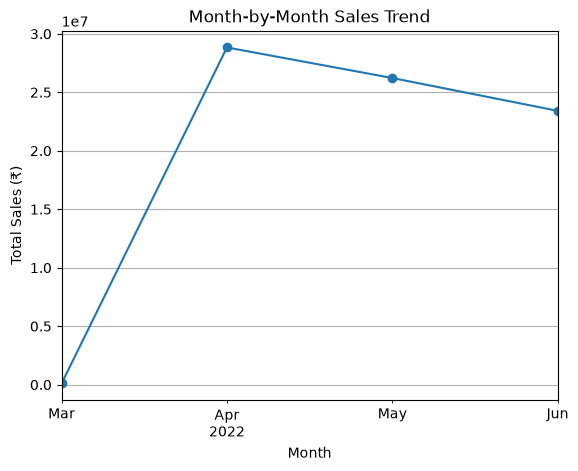

In [66]:
monthely_Sales.plot(kind='line', marker='o')
plt.title("Month-by-Month Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")
#plt.xticks(rotation=45)
plt.grid(True)
#plt.tight_layout()
plt.show()

#### How does sales change Year by year?

In [67]:
df.groupby(df['Date'].dt.to_period('Y'))['Amount'].sum()

Date
2022    78575172.94
Freq: Y-DEC, Name: Amount, dtype: float64

In [68]:
#### Which month generated the highest recorded sales?
highest_sale_month=df.groupby(df['Date'].dt.to_period('M'))['Amount'].sum()
print('highest sales month is',highest_sale_month.idxmax())
print('highest sales month revenue is',highest_sale_month.max())

highest sales month is 2022-04
highest sales month revenue is 28833945.96


## 2. Product Analysis


#### ###1. Which category generates the highest sales?

In [69]:


category_salesc = df.groupby("Category")["Amount"].sum()

highest_category = category_salesc.idxmax()
highest_sales = category_salesc.max()

print("Highest Sales Category is:", highest_category)
print("Sales amount is:", highest_sales)

Highest Sales Category is: Set
Sales amount is: 39196086.67


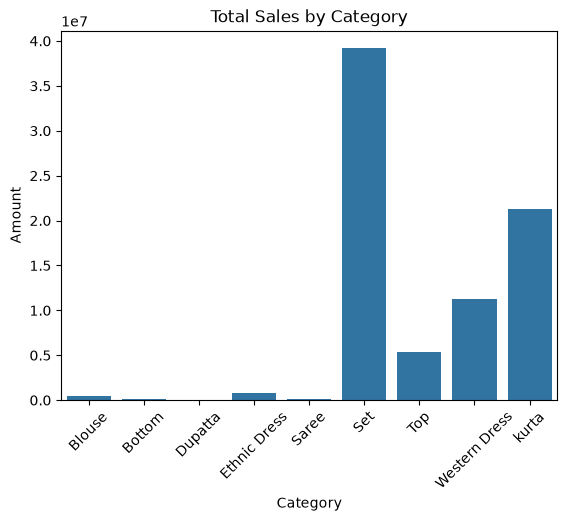

In [70]:
category_sales = df.groupby("Category", as_index=False)["Amount"].sum()

sns.barplot(
    data=category_sales,
    x="Category",
    y="Amount"
)

plt.title("Total Sales by Category")
plt.xticks(rotation=45)
plt.show()

#### 2. Which category has the highest quantity sold?

In [71]:
category_highest_Qty = df.groupby("Category")["Qty"].sum()

highest_Qty = category_highest_Qty.idxmax()
highest_Qty_amount = category_highest_Qty.max()

print("Highest Sales Quantity is:", highest_Qty)
print("Sales amount is:", highest_Qty_amount)

Highest Sales Quantity is: Set
Sales amount is: 45288


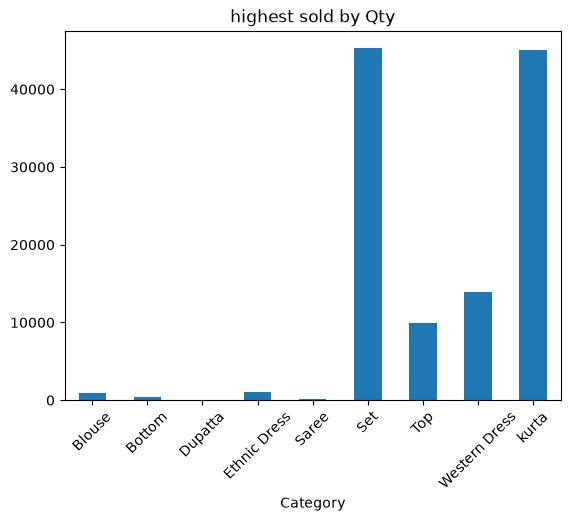

In [72]:
category_highest_Qty.plot(kind='bar')
plt.title("highest sold by Qty")
plt.xticks(rotation=45)
plt.show()

#### 3. Which category has the highest number of orders?


In [73]:
category_highest_order = df.groupby("Category")["Order ID"].nunique()
print("category with highest sales is:",category_highest_order.idxmax())
print("Number of total order is:",category_highest_order.max())

category with highest sales is: Set
Number of total order is: 47836


#### What percentage of total sales comes from each category?

In [74]:
category_highest= df.groupby("Category")["Amount"].sum()
total_sales_per=(category_highest/category_highest.sum())*100
print(total_sales_per)

Category
Blouse            0.583401
Bottom            0.191750
Dupatta           0.001164
Ethnic Dress      1.005868
Saree             0.157726
Set              49.883551
Top               6.805257
Western Dress    14.269677
kurta            27.101605
Name: Amount, dtype: float64


In [75]:
# in shorted order
category_highest= df.groupby("Category")["Amount"].sum()
total_sales_per=(category_highest/category_highest.sum())*100

print(total_sales_per.sort_values(ascending=False).round(2))

Category
Set              49.88
kurta            27.10
Western Dress    14.27
Top               6.81
Ethnic Dress      1.01
Blouse            0.58
Bottom            0.19
Saree             0.16
Dupatta           0.00
Name: Amount, dtype: float64


#### Which categories have relatively low sales?


In [76]:
category_sales = df.groupby("Category")["Amount"].sum()

lowest_category = category_sales.idxmin()
lowest_sales = category_sales.min()

print("Category with Lowest Sales is:", lowest_category)
print("Total Sales is:", lowest_sales)

Category with Lowest Sales is: Dupatta
Total Sales is: 915.0


### Product / Style


#### Which styles/products generate the highest sales?

In [77]:
style_sales = df.groupby("Style")["Amount"].sum()

highest_style =style_sales.idxmin()
highest_style_amount= style_sales.min()

print("Style with Lowest Sales is:", highest_style)
print("Total Sales is:", highest_style_amount)

Style with Lowest Sales is: BL091
Total Sales is: 0.0


In [78]:
df.head(2)

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,Amount_clean,Promotion_Status
0,171-7326790-9044369,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3614,JNE3614-KR-L,kurta,L,...,INR,453.0,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,453.0,Promotion
1,171-7326790-9044369,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3294,JNE3294-KR-L,kurta,L,...,INR,353.0,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,353.0,Promotion


#### Which products have the highest quantity sold?

In [79]:
product_quantity = df.groupby("Style")["Qty"].sum()

highest_product = product_quantity.idxmax()
highest_quantity = product_quantity.max()

print("Product with Highest Quantity Sold is:", highest_product)
print("Total Quantity Sold is:", highest_quantity)

Product with Highest Quantity Sold is: JNE3797
Total Quantity Sold is: 3693


#### Which products have the highest number of orders?


In [80]:
product_quantity = df.groupby("Style")["Order ID"].nunique()

highest_product = product_quantity.idxmax()
highest_quantity = product_quantity.max()

print("Product with Highest number Sold:", highest_product)
print("Total Quantity Sold:", highest_quantity)

Product with Highest number Sold: JNE3797
Total Quantity Sold: 4205


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128949 non-null  str           
 1   Date                128949 non-null  datetime64[us]
 2   Status              128949 non-null  str           
 3   Fulfilment          128949 non-null  str           
 4   Sales Channel       128949 non-null  str           
 5   ship-service-level  128949 non-null  str           
 6   Style               128949 non-null  str           
 7   SKU                 128949 non-null  str           
 8   Category            128949 non-null  str           
 9   Size                128949 non-null  str           
 10  ASIN                128949 non-null  str           
 11  Courier Status      128949 non-null  str           
 12  Qty                 128949 non-null  int64         
 13  currency            128949 non-null  str

#### 9. Which products have low sales but high quantity?


#### 10. Which products contribute most to total revenue?


In [82]:
# for finding the revenue of each product
product_revenue= df.groupby('Style')['Amount'].sum()
product_revenue.sort_values(ascending=False)

Style
JNE3797    2933482.00
J0230      1944948.48
SET268     1303923.56
J0341      1275322.87
J0003       981973.75
              ...    
J0324            0.00
JNE2058          0.00
SAR182           0.00
BL091            0.00
SAR060           0.00
Name: Amount, Length: 1377, dtype: float64

In [83]:
# it is also find the total revenue 
Total_revenue=product_revenue.sum()

In [84]:
# for finding the total revenue
df['Amount'].sum()

np.float64(78575172.94)

In [85]:
# finding the what perecnt of each part contribute into total revenue
revenue_percentage=(product_revenue/Total_revenue)*100
Total_contribution=revenue_percentage.sort_values(ascending=False).round(2)

In [86]:
print('Total_contribution is',Total_contribution.idxmax())
print('Total Contribution in percent is:', Total_contribution.max())

Total_contribution is JNE3797
Total Contribution in percent is: 3.73


## Size

####  Which size sells the most?

In [87]:
df['Size'].value_counts()

Size
M       22705
L       22124
XL      20879
XXL     18089
S       17092
3XL     14811
XS      11157
6XL       737
5XL       550
4XL       426
Free      379
Name: count, dtype: int64

In [88]:
sell_count=df['Size'].value_counts()
print('most sell size is:',sell_count.idxmax())
print('most sell size is:',sell_count.max())

most sell size is: M
most sell size is: 22705


#### Which size generates the highest revenue?

In [89]:
size_revenue=df.groupby('Size')['Amount'].sum()
print(size_revenue.idxmax())
print(size_revenue.max())

M
13904887.01


#### What percentage of sales comes from each size?

In [90]:
size_revenue=df.groupby('Size')['Amount'].sum()
size_sales_percentage=(size_revenue/Total_revenue)*100

In [91]:
size_sales_percentage.sort_values(ascending=False)

Size
M       17.696286
L       16.837618
XL      15.864952
XXL     13.531280
S       13.525289
3XL     11.650634
XS       8.933344
6XL      0.732681
5XL      0.541083
4XL      0.425061
Free     0.261773
Name: Amount, dtype: float64

## 3. Geographic Analysis

In [92]:
df.head(2)

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,Amount_clean,Promotion_Status
0,171-7326790-9044369,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3614,JNE3614-KR-L,kurta,L,...,INR,453.0,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,453.0,Promotion
1,171-7326790-9044369,2022-03-31,Shipped,Amazon,Amazon.in,Expedited,JNE3294,JNE3294-KR-L,kurta,L,...,INR,353.0,ARANI TIRUVANNAMALAI DISTRICT,TAMIL NADU,632317.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,353.0,Promotion


In [93]:
# Which state generates the highest sales?
sales_count=df.groupby('ship-state')['Amount'].sum()
print('Highest sales generated sales is:',sales_count.idxmax())
print('highest sales is:',sales_count.max())

Highest sales generated sales is: MAHARASHTRA
highest sales is: 13333256.14


In [94]:
# Which states have the highest number of orders?
sales_count=df.groupby('ship-state')['Order ID'].nunique()
print('Highest sales generated sales is:',sales_count.idxmax())
print('highest sales is:',sales_count.max())

Highest sales generated sales is: MAHARASHTRA
highest sales is: 20777


In [95]:
#  What percentage of total sales comes from each state?
total_sales_count=sales_count.sum()
total_percent=(sales_count/total_sales_count)*100
print('totalsales precent is:',total_percent)

totalsales precent is: ship-state
ANDAMAN & NICOBAR    0.201124
ANDHRA PRADESH       4.137163
APO                  0.000831
AR                   0.000831
ARUNACHAL PRADESH    0.106379
                       ...   
goa                  0.003324
orissa               0.000831
punjab               0.010804
rajasthan            0.004155
rajsthan             0.000831
Name: Order ID, Length: 69, dtype: float64


In [96]:
#  Which states have relatively low sales?
low_sales=total_percent.idxmin()
low_sales_value=total_percent.min()
print("Low sales of the state is:",low_sales)
print('Low sales of state value is:',low_sales_value)

Low sales of the state is: APO
Low sales of state value is: 0.0008310893919750009


In [97]:
state_sales = df.groupby("ship-state")["Amount"].sum()
state_sales_percentage = (state_sales / state_sales.sum()) * 100

low_sales_states = state_sales_percentage.sort_values().head(10)
print(low_sales_states)

ship-state
APO                       0.000000
PB                        0.000508
Rajsthan                  0.000564
AR                        0.000628
rajsthan                  0.000663
Pondicherry               0.000673
Punjab/Mohali/Zirakpur    0.000723
Puducherry                0.000723
orissa                    0.000760
Arunachal pradesh         0.000766
Name: Amount, dtype: float64


In [98]:
# Which cities generate the highest sales
city_sales=df.groupby('ship-city')['Amount'].sum()
highest_sales=city_sales.idxmax()
highest_value=city_sales.max()
print(highest_sales)
print(highest_value)

BENGALURU
6846485.99


In [99]:
# Which cities have the highest number of orders?
order_city=df.groupby('ship-city')['Order ID'].nunique()
print(order_city.idxmax())
print(order_city.max())

BENGALURU
10452


In [100]:
# Which cities have the highest quantity sold?
highest_qty_sold=df.groupby('ship-city')['Qty'].sum()
print(highest_qty_sold.idxmax())
print(highest_qty_sold.max())

BENGALURU
10420


## 4. Order & Operational Analysis

In [101]:
# How many orders were shipped?
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128949 non-null  str           
 1   Date                128949 non-null  datetime64[us]
 2   Status              128949 non-null  str           
 3   Fulfilment          128949 non-null  str           
 4   Sales Channel       128949 non-null  str           
 5   ship-service-level  128949 non-null  str           
 6   Style               128949 non-null  str           
 7   SKU                 128949 non-null  str           
 8   Category            128949 non-null  str           
 9   Size                128949 non-null  str           
 10  ASIN                128949 non-null  str           
 11  Courier Status      128949 non-null  str           
 12  Qty                 128949 non-null  int64         
 13  currency            128949 non-null  str

In [103]:
shipped_orders = df[df["Status"] == "Shipped"]["Order ID"].nunique()
print("Number of shipped orders:", shipped_orders)

Number of shipped orders: 72789


In [106]:
#How many orders were cancelled?
Cancell_orders = df[df["Status"] == "Cancelled"]["Order ID"].nunique()
print("Number of Cancelled orders:", Cancell_orders)

Number of Cancelled orders: 17196


In [ ]:
#How many orders were cancelled?
Cancell_orders = df[df["Status"] == "Cancelled"]["Order ID"].nunique()
print("Number of Cancelled orders:", Cancell_orders)

In [111]:
#How many orders were returned to seller?
Returned_to_Seller = df[df["Status"] == "Shipped - Returned to Seller"]["Order ID"].nunique()
print("Number of Returned to Seller  orders:", Returned_to_Seller)

Number of Returned to Seller  orders: 1851


In [109]:
df['Status'].unique()

<ArrowStringArray>
[                      'Shipped',                     'Cancelled',
  'Shipped - Delivered to Buyer',  'Shipped - Returned to Seller',
   'Shipped - Rejected by Buyer',                       'Pending',
           'Shipped - Picked Up', 'Shipped - Returning to Seller',
    'Shipped - Out for Delivery',     'Shipped - Lost in Transit',
                      'Shipping',             'Shipped - Damaged',
 'Pending - Waiting for Pick Up']
Length: 13, dtype: str

In [114]:
Total_order=df['Status'].count()

In [115]:
#What is the cancellation rate?
Cancellation_rate=(Cancell_orders/Total_order)*100
Cancellation_rate

np.float64(13.33550473442989)